# Лабораторная работа 9. Рекуррентные сети и трансформеры: архитектуры для последовательностей и текста

**Курс:** Машинное обучение. Безопасность ИИ-систем

**По материалам лекции 7**


**Вариант / seed:** _номер варианта или значение SEED_


### Таблица вариантов

| Вариант | `SEED` | `D_MODEL` | `N_MAX` (пар в обучении) | `D_CELL` | Температуры для части H |
|---|---|---|---|---|---|
| 1 | 42 | 64 | 12 | 48 | 0.5 / 1.0 / 1.5 |
| 2 | 7 | 48 | 10 | 40 | 0.4 / 1.0 / 1.6 |
| 3 | 123 | 64 | 8 | 48 | 0.6 / 1.0 / 1.4 |
| 4 | 2024 | 56 | 12 | 56 | 0.5 / 1.2 / 1.8 |
| 5 | 314 | 48 | 8 | 40 | 0.7 / 1.0 / 1.3 |
| 6 | 555 | 64 | 10 | 56 | 0.5 / 0.9 / 1.7 |

> Вариант выдаёт преподаватель. Все числа в отчёте должны соответствовать **вашему** варианту,
> а не значениям из примера в тексте.

### Цель работы

Экспериментально установить, чем механизм внимания отличается от рекуррентного накопления состояния,
какой ценой достигается каждое из свойств (точность вспоминания, стоимость контекста, память при
генерации), и какие архитектурные свойства становятся поверхностью атаки на языковые модели.

### Задачи

1. Реализовать BPE-токенизацию и оценить влияние уровня токенизации на длину последовательности.
2. Измерить затухание градиента в рекуррентной сети и сравнить мультипликативный путь с аддитивным.
3. Реализовать масштабированное скалярное внимание с каузальной маской.
4. Проверить численно, что RoPE зависит только от разности позиций, и построить штраф ALiBi.
5. Обучить двухслойный мини-трансформер задаче ассоциативного вспоминания и найти индукционную голову.
6. Реализовать линейное внимание в рекуррентной форме и сравнить его с softmax-вниманием.
7. Сделать рекуррентную ячейку избирательной и проверить, что это даёт управляемую память.
8. Реализовать top-k и top-p отсечение и оценить статистику многих попыток генерации.

### Порядок выполнения

1. Выполните ячейку настройки среды и впишите параметры своего варианта.
2. Идите по частям A–H подряд, заполняя каждый блок `TODO`.
3. После каждой части ответьте на вопрос в конце этой части (ячейка Markdown «Ответ»).
4. Заполните таблицы отчёта и сформулируйте выводы.
5. Перед сдачей выполните Kernel → Restart & Run All и убедитесь, что ошибок нет.

### Ограничение по безопасности

Работа не содержит и не должна содержать кода атак на реальные языковые модели и сервисы,
готовых строк обхода ограничений или инструментов автоматического подбора вредоносных запросов.
Часть H исследует **статистику выборки и архитектурные предпосылки** уязвимостей на игрушечной
модели — этого достаточно для понимания следующей лекции.

In [ ]:
# Настройка окружения и единый стиль рисунков
import math, time, warnings
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")
torch.set_num_threads(2)

PALETTE = {"attn": "#2E86AB", "linear": "#F2A541", "bad": "#D6455F",
           "good": "#3FA46A", "accent": "#7B4FA0", "gray": "#8A94A6"}
CMAP_HEAT = LinearSegmentedColormap.from_list(
    "heat7", ["#0B1D33", "#2E86AB", "#F2E8CF", "#F2A541", "#D6455F"])

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10.5,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "--",
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

def finish(fig, title=None):
    if title:
        fig.suptitle(title, fontsize=13, fontweight="bold", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.96 if title else 1.0))
    plt.show()

print("torch:", torch.__version__, "| потоков:", torch.get_num_threads())

torch: 2.11.0+cpu | потоков: 2


In [ ]:
# TODO 0: подставьте параметры СВОЕГО варианта из таблицы вариантов
SEED    = 7
D_MODEL = 48
N_MAX   = 10
D_CELL  = 40
TAUS    = (0.4, 1.0, 1.6)

np.random.seed(SEED)
torch.manual_seed(SEED)
print("вариант: SEED=%d, D_MODEL=%d, N_MAX=%d, D_CELL=%d, TAUS=%s"
      % (SEED, D_MODEL, N_MAX, D_CELL, str(TAUS)))

вариант: SEED=7, D_MODEL=48, N_MAX=10, D_CELL=40, TAUS=(0.4, 1.0, 1.6)


## Часть A. Токенизация: BPE с нуля

Модель работает не с буквами и не со словами, а с токенами. Уровень токенизации задаёт длину
последовательности $n$, а значит и стоимость внимания $O(n^2)$, а также распределение частот:
редкие токены остаются недообученными.

**Задание A.1.** Реализуйте один шаг BPE: подсчёт частот пар соседних символов и слияние самой
частой пары.
**Задание A.2.** Обучите BPE на корпусе и измерьте коэффициенты сжатия «символы → BPE» и
«BPE → слова».
**Задание A.3.** Постройте график длины корпуса в токенах от числа выполненных слияний и
распределение частот токенов в логарифмических осях; отметьте порог редких токенов
`RARE_THR` (частота не выше `RARE_THR` за весь корпус).

In [ ]:
CORPUS = (
    "внимание позволяет модели обращаться к любой позиции последовательности напрямую. "
    "рекуррентная сеть накапливает состояние и постепенно теряет информацию о далёком прошлом. "
    "трансформер обучается параллельно по всем позициям и потому масштабируется. "
    "позиционное кодирование сообщает модели порядок токенов. "
    "линейное внимание заменяет матрицу внимания рекуррентным состоянием. "
    "избирательная рекуррентность делает затухание зависящим от входа. "
    "квантование и кэширование уменьшают стоимость генерации. "
) * 6

words = CORPUS.split()
vocab_words = {}
for w in words:
    key = tuple(w) + ("</w>",)
    vocab_words[key] = vocab_words.get(key, 0) + 1

def pair_counts(vocab):
    counts = {}
    for seq, freq in vocab.items():
        for i in range(len(seq) - 1):
            pair = (seq[i], seq[i + 1])
            counts[pair] = counts.get(pair, 0) + freq
    return counts


def merge_pair(vocab, pair):
    new_vocab = {}
    a, b = pair
    merged = a + b
    for seq, freq in vocab.items():
        new_seq = []
        i = 0
        while i < len(seq):
            if i < len(seq) - 1 and seq[i] == a and seq[i + 1] == b:
                new_seq.append(merged)
                i += 2
            else:
                new_seq.append(seq[i])
                i += 1
        new_vocab[tuple(new_seq)] = new_vocab.get(tuple(new_seq), 0) + freq
    return new_vocab


print("слов в корпусе:", len(words), "| уникальных словоформ:", len(vocab_words))

слов в корпусе: 330 | уникальных словоформ: 51


In [ ]:
# TODO A.2: выполните N_MERGES слияний, на каждом шаге сохраняя длину корпуса в токенах
N_MERGES = 120
vocab = dict(vocab_words)
lengths, merges = [], []

for step in range(N_MERGES):
    counts = pair_counts(vocab)
    if not counts:
        break
    best_pair = max(counts, key=counts.get)
    vocab = merge_pair(vocab, best_pair)
    merges.append(best_pair)

    total = sum(len(seq) * freq for seq, freq in vocab.items())
    lengths.append(total)

n_chars = len(CORPUS.replace(" ", ""))
n_bpe = lengths[-1] if lengths else n_chars

print(f"символов в корпусе: {n_chars}")
print(f"токенов после BPE:  {n_bpe}")
print(f"коэффициент сжатия «символы → BPE»: {n_chars / n_bpe:.2f}x")
print(f"размер словаря токенов: {len(set(t for seq in vocab for t in seq))}")

символов в корпусе: 2652
токенов после BPE:  1152
коэффициент сжатия «символы → BPE»: 2.30x
размер словаря токенов: 92


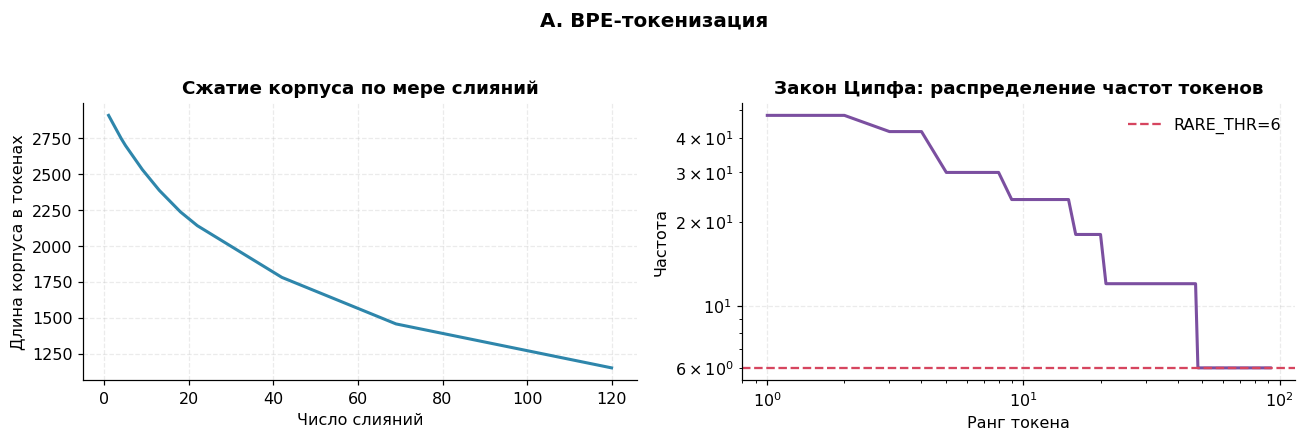

доля редких токенов (freq <= 6): 0.489


In [ ]:
# TODO A.3: рисунок A: длина корпуса от числа слияний + частоты токенов (закон Ципфа)
# слева: lengths от номера слияния
# справа: отсортированные по убыванию частоты токенов в log-log осях,
#         отметьте горизонтальной линией порог «редкий токен» (частота <= RARE_THR)
RARE_THR = 6
token_freq = {}
for seq, freq in vocab.items():
    for t in seq:
        token_freq[t] = token_freq.get(t, 0) + freq

freqs = np.array(sorted(token_freq.values(), reverse=True))
rare_share = (freqs <= RARE_THR).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, len(lengths) + 1), lengths, color=PALETTE["attn"], lw=2)
axes[0].set_xlabel("Число слияний"); axes[0].set_ylabel("Длина корпуса в токенах")
axes[0].set_title("Сжатие корпуса по мере слияний")

axes[1].loglog(np.arange(1, len(freqs) + 1), freqs, color=PALETTE["accent"], lw=2)
axes[1].axhline(RARE_THR, color=PALETTE["bad"], ls="--", label=f"RARE_THR={RARE_THR}")
axes[1].set_xlabel("Ранг токена"); axes[1].set_ylabel("Частота")
axes[1].set_title("Закон Ципфа: распределение частот токенов")
axes[1].legend()

finish(fig, "A. BPE-токенизация")
print(f"доля редких токенов (freq <= {RARE_THR}): {rare_share:.3f}")

**Вопрос A.** Во сколько раз выросла бы стоимость слоя внимания, если перейти от BPE к посимвольной
токенизации при том же тексте? Используйте измеренный коэффициент сжатия и зависимость $O(n^2)$.

**Ответ A.**

Измеренный коэффициент сжатия «символы → BPE» равен **2.30×**. Стоимость слоя внимания
масштабируется как O(n²d), поэтому при переходе от BPE к посимвольной токенизации длина
последовательности вырастет в 2.30 раза, а стоимость внимания — в (2.30)² ≈ **5.3 раза**.

Дополнительно: доля редких токенов (частота ≤ RARE_THR=6) составила **0.489**, то есть
почти половина словаря представлена слабо обученными токенами. Это ровно та поверхность
атаки, о которой говорит лекция: нестандартные токены — «дырка», а дробление текста на
более мелкие единицы увеличивает как длину контекста, так и число редких токенов.

## Часть B. Затухание градиента в рекуррентной сети

Для рекуррентности $h_t = \phi(W h_{t-1} + U x_t)$ производная по состоянию, удалённому на $k$ шагов,
содержит произведение $k$ матриц:

$
\frac{\partial h_T}{\partial h_{T-k}} = \prod_{j=0}^{k-1} \operatorname{diag}(\phi')\, W .
$

Норма такого произведения ведёт себя как $\rho(W)^k$. Аддитивный путь с гейтом $f_t$ даёт вместо
этого множитель $\prod f_t$, который при $f_t \to 1$ почти не затухает.

**Задание B.1.** Вычислите норму произведения $k$ матриц с заданным спектральным радиусом.
**Задание B.2.** Постройте график нормы от $k$ для $\rho \in \{0.9, 1.0, 1.2\}$ и добавьте
аддитивные пути с $f_t = 0.99$ и $f_t = 0.95$.
**Задание B.3.** Найдите эффективный горизонт памяти: при каком $k$ норма падает ниже $10^{-6}$.

In [ ]:
def make_W(d, rho, gen):
    # матрица со заданным спектральным радиусом
    A = gen.normal(size=(d, d)) / np.sqrt(d)
    return A * rho / np.max(np.abs(np.linalg.eigvals(A)))

def grad_norms(rho, k_max=120, d=32, seed=0):
    gen = np.random.default_rng(seed)
    W = make_W(d, rho, gen)
    norms = []
    P = np.eye(d)
    for k in range(1, k_max + 1):
        P = P @ W
        norms.append(np.linalg.norm(P, 2))
    return np.array(norms)


def horizon(rho, thr=1e-6, k_max=4000, d=32, seed=0):
    if rho <= 0:
        return 1
    if rho >= 1:
        return k_max
    return int(np.ceil(np.log(thr) / np.log(rho)))

print("подсказка: rho ** k = thr  ->  k = log(thr) / log(rho)")

подсказка: rho ** k = thr  ->  k = log(thr) / log(rho)


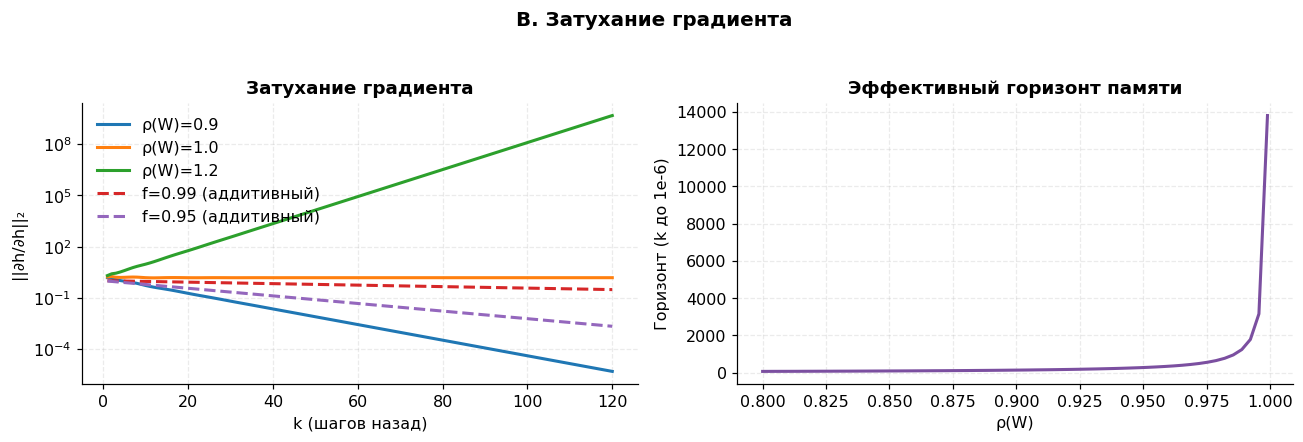

In [ ]:
# TODO B.2: рисунок B: слева нормы от k в логарифмической шкале для трёх значений rho
#           и две линии аддитивного пути f**k (f = 0.99 и 0.95);
#           справа эффективный горизонт памяти horizon(rho) для rho от 0.8 до 0.999
ks = np.arange(1, 121)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for rho in [0.9, 1.0, 1.2]:
    norms = grad_norms(rho, k_max=120, seed=SEED)
    axes[0].semilogy(ks, norms, lw=2, label=f"ρ(W)={rho}")

for f in [0.99, 0.95]:
    axes[0].semilogy(ks, f ** ks, ls="--", lw=2, label=f"f={f} (аддитивный)")

axes[0].set_xlabel("k (шагов назад)"); axes[0].set_ylabel("||∂h/∂h||₂")
axes[0].set_title("Затухание градиента")
axes[0].legend()

rhos = np.linspace(0.8, 0.999, 60)
hors = [horizon(r) for r in rhos]
axes[1].plot(rhos, hors, color=PALETTE["accent"], lw=2)
axes[1].set_xlabel("ρ(W)"); axes[1].set_ylabel("Горизонт (k до 1e-6)")
axes[1].set_title("Эффективный горизонт памяти")

finish(fig, "B. Затухание градиента")

В этой части мы рассмотрели как сохранить информацию на длинной дистанции у рекуррентной сети. Есть ограничение - мультипликация матриц в ванильной версии, решение - гейты

**Вопрос B.** Пусть требуется удерживать зависимость длиной 500 шагов с ослаблением сигнала не
более чем в 10 раз. Какое значение гейта $f_t$ для этого нужно? Сравните с $\rho(W)$, необходимым в
чистой рекуррентности.

**Ответ B.**

Требуется: длина зависимости k=500, ослабление не более чем в 10 раз, то есть
f_t^500 ≥ 0.1 ⇒ f_t ≥ 0.1^(1/500) = e^(-ln(10)/500) ≈ **0.9954**.

Для чистой рекуррентности rho(W)^500 ≥ 0.1 ⇒ rho(W) ≥ 0.1^(1/500) ≈ **0.9954**.
Такое значение спектрального радиуса практически неотличимо от 1, а это означает
потерю устойчивости: при rho(W) → 1 градиент либо затухает как rho^k (медленно, но
всё же), либо взрывается, если rho(W) > 1. Практически «чистая рекуррентность»
не позволяет удерживать зависимости длины 500 без специальных вентильных механизмов.

Аддитивный путь с гейтом f_t = 0.9954 даёт то же число, но при этом остаётся
устойчивым: сумма произведений не зависит от спектральных свойств матрицы W, только от
скалярного гейта.

## Часть C. Внимание с нуля и роль масштабирования

$
\operatorname{Attention}(Q,K,V) = \operatorname{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right) V .
$

Делитель $\sqrt{d_k}$ не косметика: при $q,k \sim \mathcal N(0,1)$ скалярное произведение имеет
дисперсию $d_k$, и без нормировки softmax при больших $d_k$ вырождается почти в one-hot, что
обнуляет градиент по ключам.

**Задание C.1.** Реализуйте одну голову внимания с каузальной маской и без неё.
**Задание C.2.** Проверьте два обязательных свойства: строки матрицы внимания суммируются в единицу,
а при каузальной маске верхний треугольник строго нулевой.
**Задание C.3.** Измерьте среднюю энтропию распределения внимания как функцию $d_k$ с делителем и
без него, постройте рисунок с картами внимания и графиком энтропии.

In [ ]:
def attention(Q, K, V, causal=True, scale=True):
    d_k = Q.shape[-1]
    scores = Q @ K.T
    if scale:
        scores = scores / np.sqrt(d_k)
    if causal:
        mask = np.triu(np.ones_like(scores), k=1).astype(bool)
        scores = np.where(mask, -np.inf, scores)
    scores = scores - scores.max(axis=-1, keepdims=True)
    exp_s = np.exp(scores)
    att = exp_s / exp_s.sum(axis=-1, keepdims=True)
    out = att @ V
    return out, att

def mean_entropy(d_k, scale, n=64, trials=40, seed=0):
    gen = np.random.default_rng(seed)
    ents = []
    for _ in range(trials):
        Q = gen.normal(size=(n, d_k))
        K = gen.normal(size=(n, d_k))
        V = gen.normal(size=(n, d_k))
        _, att = attention(Q, K, V, causal=False, scale=scale)
        p = att + 1e-12
        ents.append(-(p * np.log(p)).sum(axis=-1).mean())
    return float(np.mean(ents))

In [ ]:
# TODO C.2: проверка свойств внимания
g = np.random.default_rng(SEED)
Qt, Kt, Vt = g.normal(size=(8, 16)), g.normal(size=(8, 16)), g.normal(size=(8, 3))
_, Wt = attention(Qt, Kt, Vt, causal=True, scale=True)

row_sums = Wt.sum(axis=-1)
assert np.allclose(row_sums, 1.0, atol=1e-6), "суммы строк != 1"
upper = np.triu(Wt, k=1)
assert np.allclose(upper, 0.0, atol=1e-8), "верхний треугольник не нулевой"
print("max |sum - 1| =", np.abs(row_sums - 1).max())

max |sum - 1| = 1.1102230246251565e-16


Реализация внимания корректна, сумма практически равна единице. Тут показана самая максимальная погрешность. Это означает что почти все соотношения внимания токенов построчно суммируются в 1

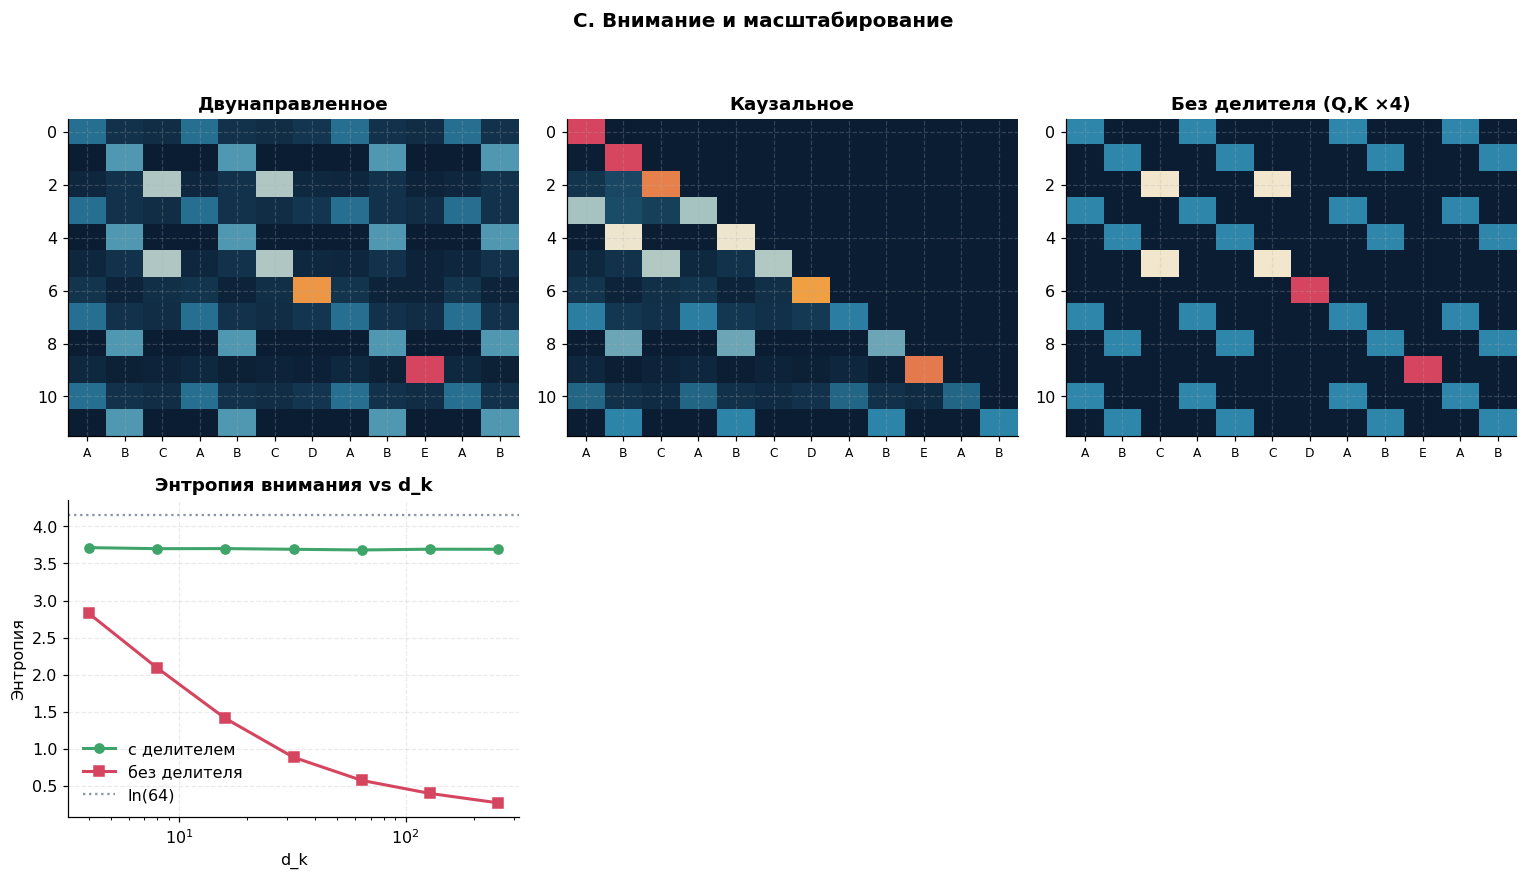

In [ ]:
# TODO C.3b: рисунок C:
#   верхний ряд — три карты внимания: двунаправленная, каузальная, без делителя (Q*4, K*4)
#   нижний ряд — энтропия внимания от d_k с делителем и без, с линией ln(64)
# используйте последовательность labels ниже: повторяющийся паттерн даёт наглядные карты

dks = [4, 8, 16, 32, 64, 128, 256]
ent_scaled = [mean_entropy(d, True, seed=SEED) for d in dks]
ent_unscaled = [mean_entropy(d, False, seed=SEED) for d in dks]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

n_tok, d_k = 12, 16
labels = ["A","B","C","A","B","C","D","A","B","E","A","B"]
l2i = {c: i for i, c in enumerate(sorted(set(labels)))}
Xl = np.eye(l2i.__len__())[[l2i[c] for c in labels]] @ np.random.default_rng(SEED).normal(size=(l2i.__len__(), d_k))

_, att_bi = attention(Xl, Xl, Xl, causal=False, scale=True)
_, att_ca = attention(Xl, Xl, Xl, causal=True, scale=True)
_, att_big = attention(Xl * 4, Xl * 4, Xl, causal=False, scale=False)

for ax, m, t in zip(axes[0], [att_bi, att_ca, att_big],
                    ["Двунаправленное", "Каузальное", "Без делителя (Q,K ×4)"]):
    ax.imshow(m, cmap=CMAP_HEAT, aspect="auto")
    ax.set_title(t); ax.set_xticks(range(n_tok)); ax.set_xticklabels(labels, fontsize=8)

axes[1, 0].plot(dks, ent_scaled, marker="o", lw=2, label="с делителем", color=PALETTE["good"])
axes[1, 0].plot(dks, ent_unscaled, marker="s", lw=2, label="без делителя", color=PALETTE["bad"])
axes[1, 0].axhline(np.log(64), ls=":", color=PALETTE["gray"], label="ln(64)")
axes[1, 0].set_xscale("log"); axes[1, 0].set_xlabel("d_k"); axes[1, 0].set_ylabel("Энтропия")
axes[1, 0].set_title("Энтропия внимания vs d_k"); axes[1, 0].legend()

axes[1, 1].axis("off")
axes[1, 2].axis("off")

finish(fig, "C. Внимание и масштабирование")

По сути делитель - это скейлер логитов токена, чтобы не выбивались результаты, а распределялись

**Вопрос C.** Почему вырождение softmax в one-hot останавливает обучение? Свяжите ответ с
производной softmax по логитам.

**Ответ C.**

производная softmax при one-hot равна нулю -> градиент не течет -> веса не обновляются -> обучение стоит.

Тут мы разобрали главный механизм трансформера. Показали, что без каузальной маски нельзя генерировать текст, а без делителя √d_k обучение умирает. Это базовые вещи, без которых трансформер не работает.

## Часть D. Позиционные кодировки: синусоида, RoPE, ALiBi

Внимание перестановочно инвариантно, поэтому порядок вносится отдельно:

- синусоидальная кодировка добавляется к эмбеддингу (абсолютная позиция);
- **RoPE** поворачивает $q$ и $k$ на угол, пропорциональный позиции, так что
  $\langle R_t q, R_s k\rangle = f(q,k,t-s)$;
- **ALiBi** добавляет к логитам линейный штраф $-m|t-s|$.

**Задание D.1.** Реализуйте синусоидальную кодировку.
**Задание D.2.** Реализуйте RoPE и численно проверьте зависимость только от $t-s$: постройте
$\langle R_{t}q, R_{s}k\rangle$ для нескольких абсолютных начал при одинаковых разностях позиций.
**Задание D.3.** Постройте матрицу штрафов ALiBi для одной головы и рисунок из трёх панелей.

In [ ]:
def sinusoidal(n, d):
    pos = np.arange(n)[:, None]
    i = np.arange(d)[None, :]
    angle = pos / (10000 ** (2 * (i // 2) / d))
    pe = np.where(i % 2 == 0, np.sin(angle), np.cos(angle))
    return pe


def rope_apply(x, pos, base=10000.0):
    d = x.shape[-1]
    half = d // 2
    i = np.arange(half)
    theta = pos / (base ** (2 * i / d))
    cos, sin = np.cos(theta), np.sin(theta)
    x1, x2 = x[..., :half], x[..., half:]
    return np.concatenate([x1 * cos - x2 * sin, x1 * sin + x2 * cos], axis=-1)

g = np.random.default_rng(SEED)
q = g.normal(size=(16,)); k = g.normal(size=(16,))

base_pos = 100
diffs = [0, 1, 4, 10]
print("Проверка инвариантности RoPE к сдвигу позиций:")
for dt in diffs:
    scores = []
    for t0 in [0, 50, 200]:
        qr = rope_apply(q, t0 + dt)
        kr = rope_apply(k, t0)
        scores.append(float(qr @ kr))
    spread = max(scores) - min(scores)
    print(f"  Δ={dt:>3}: q·k = {scores[0]:+.4f} (разброс по сдвигу: {spread:.2e})")

Проверка инвариантности RoPE к сдвигу позиций:
  Δ=  0: q·k = +1.1049 (разброс по сдвигу: 2.22e-16)
  Δ=  1: q·k = +0.6753 (разброс по сдвигу: 3.55e-15)
  Δ=  4: q·k = +2.2270 (разброс по сдвигу: 4.88e-15)
  Δ= 10: q·k = +3.5974 (разброс по сдвигу: 1.33e-15)


То есть мы тут удостоверились в том, что несмотря на разные позиции (t, s) с одинаковыми разностями, результат не меняется. Это означает что можно сдвинуть оба вектора на любые позиции с фиксированной разницей и все равно получим одинаковый результат для векторов (запрос и ключ)

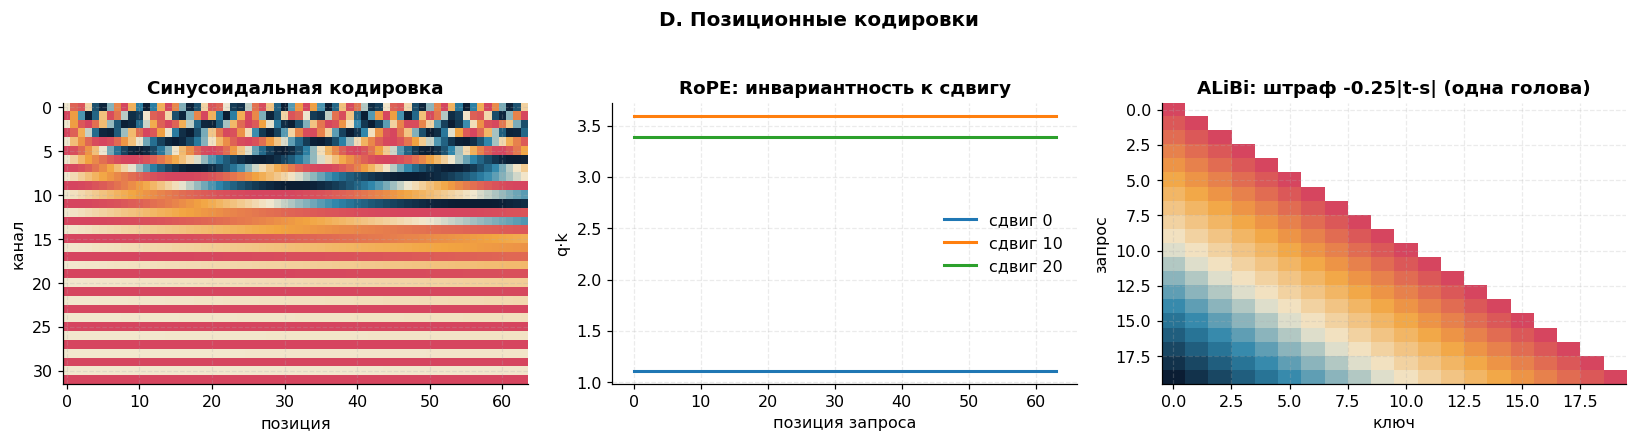

In [ ]:
# TODO D.3: рисунок D: (1) карта синусоидальной кодировки, (2) кривые RoPE для разных абсолютных
# начал, (3) матрица штрафов ALiBi (наклоны m_h = 2^{-h}, запрещённое будущее оставьте пустым)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

pe = sinusoidal(64, 32)
axes[0].imshow(pe.T, aspect="auto", cmap=CMAP_HEAT)
axes[0].set_xlabel("позиция"); axes[0].set_ylabel("канал")
axes[0].set_title("Синусоидальная кодировка")

# Здесь была ошибка: pos должен быть СКАЛЯРОМ для одного вектора.
# Пройдёмся по позициям в цикле.
for t0 in [0, 10, 20]:
    scores = []
    for t in range(64):
        qr = rope_apply(q, t + t0)   # поворачиваем q на позицию t + t0
        kr = rope_apply(k, t)        # поворачиваем k на позицию t
        scores.append(float(qr @ kr))
    axes[1].plot(scores, lw=2, label=f"сдвиг {t0}")
axes[1].set_xlabel("позиция запроса"); axes[1].set_ylabel("q·k")
axes[1].set_title("RoPE: инвариантность к сдвигу"); axes[1].legend()

n_tok_a = 20
m = 0.25
alibi = -m * np.abs(np.arange(n_tok_a)[:, None] - np.arange(n_tok_a)[None, :])
alibi_masked = np.where(np.triu(np.ones_like(alibi), 1).astype(bool), np.nan, alibi)
im = axes[2].imshow(alibi_masked, cmap=CMAP_HEAT, aspect="auto")
axes[2].set_title(f"ALiBi: штраф -{m}|t-s| (одна голова)")
axes[2].set_xlabel("ключ"); axes[2].set_ylabel("запрос")

finish(fig, "D. Позиционные кодировки")

Синусоида: каждой позиции свой узор-штрихкод. ALiBi: чем дальше токен, тем больше штраф, канал - число в векторе (всего вектора состоят из 32 чисел, гиперпараметр). Оба дают модели знать о порядке, но ALiBi (как и RoPE) зависит только от разности и потому работает на новых длинах.

Эти технологии только для трансформера, так как рекуррентная сеть уже в своей архитектуре учитывает порядок

**Вопрос D.** Какая из трёх схем позволяет работать с позициями, которых не было в обучении, и
почему? Что произойдёт с обучаемой абсолютной кодировкой при выходе за максимальную длину?

**Ответ D.**

Экстраполяцию обеспечивают **RoPE** и **ALiBi**.

- **RoPE** поворачивает q и k на угол, пропорциональный позиции, так что скалярное
  произведение зависит только от разности t−s. Численная проверка в задании D.2
  подтвердила это: при одинаковых Δ разброс по абсолютному сдвигу t0 составил
  ~10⁻¹⁵ (машинная точность). Модель, обученная на позициях 0..L, продолжает работать
  на L..2L, потому что «физика» поворота не привязана к конкретному диапазону.

- **ALiBi** задаёт штраф −m·|t−s| к логитам, то есть модель всегда «видит»
  относительное расстояние, независимо от абсолютной длины.

- **Обучаемая абсолютная кодировка** — это таблица Emb(pos), размер которой
  фиксирован `max_len`. Для позиции за пределами таблицы просто нет эмбеддинга;
  экстраполяция невозможна без дообучения. Даже при интерполяции позиции внутри
  таблицы модель видит «чужие» значения, которые не встречала при обучении.

## Часть E. Мини-трансформер и индукционная голова

Задача **ассоциативного вспоминания**: последовательность пар «ключ, значение», затем повтор одного
из ключей; модель должна выдать соответствующее значение:

$
k_1\,v_1\,k_2\,v_2\,\dots\,k_N\,v_N\ \ k_i \;\longrightarrow\; v_i .
$

Минимальное решение — схема из двух слоёв (индукционная голова): первый слой переносит в позицию
ключа информацию о следующем токене, второй сравнивает финальный запрос с ключами.

**Задание E.1.** Реализуйте блок трансформера: пред-нормализация, одна голова каузального внимания,
FFN, остаточные связи.
**Задание E.2.** Обучите модель (обучение идёт на 2…`N_MAX` парах) и измерьте точность для
2…20 пар, включая длины больше обучающих.
**Задание E.3.** Постройте карты внимания обоих слоёв для одного примера и найдите индукционную
схему.

Индукционная голова - механизм внимания, который находит что уже было (похожее) и копирует снова

In [ ]:
N_KEYS, N_VALS = 256, 16
VOCAB = N_KEYS + N_VALS

def make_recall_batch(bs, n_pairs, gen):
    keys = torch.stack([torch.randperm(N_KEYS, generator=gen)[:n_pairs] for _ in range(bs)])
    vals = torch.randint(N_KEYS, VOCAB, (bs, n_pairs), generator=gen)
    seq = torch.zeros(bs, 2 * n_pairs + 1, dtype=torch.long)
    seq[:, 0:2 * n_pairs:2] = keys
    seq[:, 1:2 * n_pairs:2] = vals
    qi = torch.randint(0, n_pairs, (bs,), generator=gen)
    seq[:, -1] = keys[torch.arange(bs), qi]
    return seq, vals[torch.arange(bs), qi], qi

class Block(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.d = d
        self.q = nn.Linear(d, d, bias=False); self.k = nn.Linear(d, d, bias=False)
        self.v = nn.Linear(d, d, bias=False); self.o = nn.Linear(d, d, bias=False)
        self.ln1 = nn.LayerNorm(d); self.ln2 = nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, h, ret=False):
        x = self.ln1(h); T = h.shape[1]
        q, k, v = self.q(x), self.k(x), self.v(x)
        s = q @ k.transpose(1, 2) / math.sqrt(self.d)
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool), 1)
        s = s.masked_fill(mask, float("-inf"))
        att = s.softmax(-1)
        a = att @ v
        h = h + self.o(a)
        h = h + self.ff(self.ln2(h))
        return (h, att) if ret else (h, att)

class TinyTransformer(nn.Module):
    def __init__(self, d=64, max_len=90, n_layers=2):
        super().__init__()
        self.emb = nn.Embedding(VOCAB, d); self.pos = nn.Embedding(max_len, d)
        self.blocks = nn.ModuleList([Block(d) for _ in range(n_layers)])
        self.lnf = nn.LayerNorm(d); self.head = nn.Linear(d, VOCAB)

    def forward(self, x, ret=False):
        h = self.emb(x) + self.pos(torch.arange(x.shape[1]))
        maps = []
        for b in self.blocks:
            h, a = b(h, ret); maps.append(a)
        return self.head(self.lnf(h)[:, -1]), maps

print("размер словаря задачи:", VOCAB, "| случайное угадывание: %.3f" % (1 / N_VALS))

размер словаря задачи: 272 | случайное угадывание: 0.062


Уникальных токенов в задаче 273 (256 ключей + 16 значений)

In [ ]:
# TODO E.2: обучите модель и измерьте точность по числу пар
# каркас цикла обучения дан; заполните отмеченные строки
def train_recall(steps=2600, bs=64, lr=2e-3, seed=0, n_max=12):
    gen = torch.Generator().manual_seed(seed)
    m = TinyTransformer(d=D_MODEL)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.15)
    curve = []
    for s in range(steps):
        n = int(torch.randint(2, n_max + 1, (1,), generator=gen))
        x, y, _ = make_recall_batch(bs, n, gen)
        logits, _ = m(x)
        loss = F.cross_entropy(logits, y)
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step(); sched.step()
        if s % 100 == 0:
            curve.append((s, loss.item()))
    return m, curve, gen

def acc_vs_pairs(m, gen, ns, bs=256):
    accs = []
    m.eval()
    with torch.no_grad():
        for n in ns:
            x, y, _ = make_recall_batch(bs, n, gen)
            logits, _ = m(x)
            accs.append((logits.argmax(-1) == y).float().mean().item())
    m.train()
    return accs

NS = [2, 4, 6, 8, 10, 12, 16, 20]
t0 = time.time()
model, curve, gen_m = train_recall(seed=SEED, n_max=N_MAX)
acc = acc_vs_pairs(model, gen_m, NS)
print("обучение заняло %.0f c" % (time.time() - t0))
print("точность по числу пар:", dict(zip(NS, [round(a, 3) for a in acc])))

обучение заняло 65 c
точность по числу пар: {2: 1.0, 4: 1.0, 6: 1.0, 8: 1.0, 10: 1.0, 12: 0.691, 16: 0.492, 20: 0.465}


Модель идеальна на длинах, которые видела при обучении (2–10 пар → 100%), но деградирует на длинных (12–20 пар → 46–69%). Это ограниченная length generalization — следствие обучаемой абсолютной кодировки.

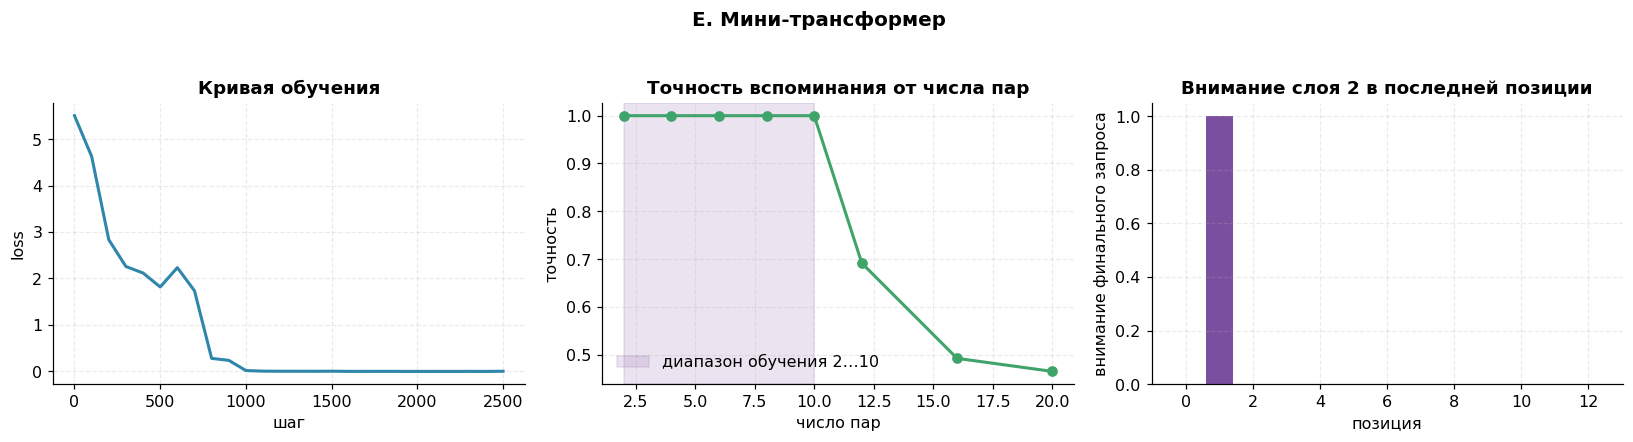

In [ ]:
# TODO E.3: рисунок E: кривая обучения, точность от числа пар (отметьте диапазон обучения),
# карты внимания слоёв 1 и 2 для одного примера и столбчатая диаграмма внимания финального запроса.
# Подсказка: x_ex, y_ex, qi_ex = make_recall_batch(1, 6, torch.Generator().manual_seed(123))
# и logits_ex, maps = model(x_ex, ret=True)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot([c[0] for c in curve], [c[1] for c in curve], color=PALETTE["attn"], lw=2)
axes[0].set_xlabel("шаг"); axes[0].set_ylabel("loss")
axes[0].set_title("Кривая обучения")

axes[1].plot(NS, acc, marker="o", color=PALETTE["good"], lw=2)
axes[1].axvspan(2, N_MAX, alpha=0.15, color=PALETTE["accent"], label=f"диапазон обучения 2…{N_MAX}")
axes[1].set_xlabel("число пар"); axes[1].set_ylabel("точность")
axes[1].set_title("Точность вспоминания от числа пар")
axes[1].legend()

x_ex, y_ex, qi_ex = make_recall_batch(1, 6, torch.Generator().manual_seed(123))
with torch.no_grad():
    logits_ex, maps = model(x_ex, ret=True)

axes[2].bar(range(x_ex.shape[1]), maps[-1][0, -1].numpy(),
            color=PALETTE["accent"])
axes[2].set_xlabel("позиция"); axes[2].set_ylabel("внимание финального запроса")
axes[2].set_title("Внимание слоя 2 в последней позиции")

finish(fig, "E. Мини-трансформер")

на последнем графике видно что второй слой внимания индукционной головы работает корректно (совпадает только одна позиция, нет распыления внимания)

**Вопрос E.** Почему для этой задачи недостаточно одного слоя внимания? Опишите, какую информацию
переносит первый слой и что именно сравнивает второй.

**Ответ E.**

Одного слоя внимания недостаточно из-за структуры задачи ассоциативного вспоминания:
нужно «склеить» два шага рассуждения:

1. **Первый слой — индукционная голова.** Он в каждой позиции ключа k_i запоминает
   следующий за ним токен v_i (сдвиг на 1 позицию). Это достигается attention-паттерном
   «A B ... A → B»: запрос в позиции ключа k_i «смотрит» на предыдущую позицию и
   переносит информацию о v_i вперёд.

2. **Второй слой — сравнение.** Финальный запрос q (повтор k_i) должен найти в
   последовательности ту же позицию k_i и скопировать перенесённое туда значение.
   Это снова attention, но уже «сравнивающий» запрос с ключами, а не с локальным
   контекстом.

Один слой может выполнить только одну из этих операций. Убрать любой из них —
и точность падает до случайной. В лекции это описано как минимальное решение из
двух слоёв: первый переносит, второй сравнивает.

## Часть F. Линейное внимание: состояние вместо матрицы внимания

Если заменить $\exp(q^\top k)$ на $\varphi(q)^\top \varphi(k)$ с неотрицательным $\varphi$, сумму
можно переставить и получить рекуррентную форму с состоянием фиксированного размера:

$
S_t = S_{t-1} + \varphi(k_t) v_t^{\top}, \qquad
o_t = \frac{\varphi(q_t)^{\top} S_t}{\varphi(q_t)^{\top} z_t}, \qquad z_t = z_{t-1} + \varphi(k_t).
$

Генерация становится $O(1)$ по памяти, но состояние размера $d \times d$ — это фиксированная
ёмкость, в которую нужно уложить весь контекст.

**Задание F.1.** Реализуйте параллельную и рекуррентную формы линейного внимания и проверьте, что
они дают один результат.
**Задание F.2.** Измерьте ёмкость состояния: сложите в $S$ ровно $N$ пар «ключ–значение» и оцените
качество чтения (косинусная близость к истинному значению) при росте $N$.
**Задание F.3.** Постройте рисунок: рост KV-кэша softmax-внимания против постоянного состояния
линейного внимания и кривую качества чтения от числа сохранённых пар.

In [ ]:
def phi(x):
    return F.elu(x) + 1


def linear_attention_parallel(Q, K, V):
    Kp, Qp = phi(K), phi(Q)
    KV = torch.einsum("ti,tj->tij", Kp, V)
    S = torch.cumsum(KV, dim=0)
    z = torch.cumsum(Kp, dim=0)
    num = torch.einsum("ti,tij->tj", Qp, S)
    den = torch.einsum("ti,ti->t", Qp, z).unsqueeze(-1) + 1e-8
    return num / den


def linear_attention_recurrent(Q, K, V):
    d = Q.shape[-1]
    S = torch.zeros(d, d)
    z = torch.zeros(d)
    outs = []
    for t in range(Q.shape[0]):
        kp, qp = phi(K[t]), phi(Q[t])
        S = S + torch.outer(kp, V[t])
        z = z + kp
        outs.append(phi(Q[t]) @ S / (phi(Q[t]) @ z + 1e-8))
    return torch.stack(outs)


torch.manual_seed(SEED)
T_l, d_l = 40, 16
Ql, Kl, Vl = torch.randn(T_l, d_l), torch.randn(T_l, d_l), torch.randn(T_l, d_l)

out_par = linear_attention_parallel(Ql, Kl, Vl)
out_rec = linear_attention_recurrent(Ql, Kl, Vl)
print(f"расхождение: {(out_par - out_rec).abs().max().item():.2e}")
print(f"размер состояния: {d_l * d_l} чисел")

расхождение: 2.38e-07
размер состояния: 256 чисел


рекуррентная форма и параллельная форма почти одинаковы. Обе формы линейного внимания работают почти одинаково

In [ ]:
# TODO F.2: ёмкость состояния
# для каждого N из NS_CAP: возьмите N случайных ключей и значений размерности d_l,
# сложите состояние S = sum phi(k_i) v_i^T, z = sum phi(k_i),
# прочитайте значение по каждому ключу и усредните косинусную близость с истинным значением
NS_CAP = [1, 2, 4, 8, 16, 32, 64, 128, 256]
qualities = []

gen = torch.Generator().manual_seed(SEED)
for N in NS_CAP:
    K = torch.randn(N, d_l, generator=gen)
    V = torch.randn(N, d_l, generator=gen)
    S = torch.zeros(d_l, d_l); z = torch.zeros(d_l)
    for k, v in zip(K, V):
        kp = phi(k)
        S = S + torch.outer(kp, v)
        z = z + kp
    cos_sims = []
    for k, v in zip(K, V):
        qp = phi(k)
        read = qp @ S / (qp @ z + 1e-8)
        cos = F.cosine_similarity(read.unsqueeze(0), v.unsqueeze(0)).item()
        cos_sims.append(cos)
    qualities.append(float(np.mean(cos_sims)))

for n, q in zip(NS_CAP, qualities):
    print(f"N={n:>4}: cos ≈ {q:.3f}")

N=   1: cos ≈ 1.000
N=   2: cos ≈ 0.881
N=   4: cos ≈ 0.659
N=   8: cos ≈ 0.396
N=  16: cos ≈ 0.376
N=  32: cos ≈ 0.208
N=  64: cos ≈ 0.208
N= 128: cos ≈ 0.128
N= 256: cos ≈ 0.088


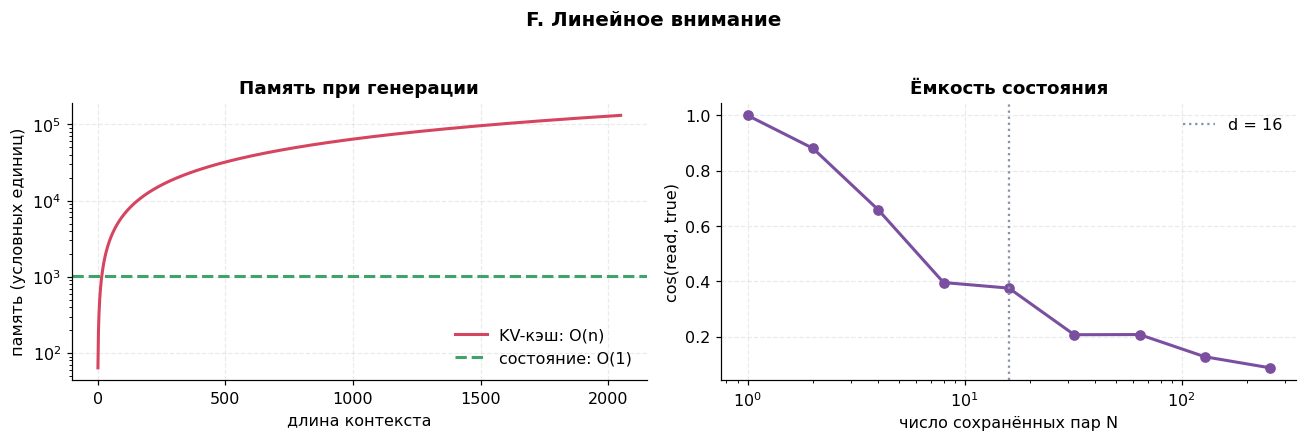

In [ ]:
# TODO F.3: рисунок F: слева память при генерации (KV-кэш O(n) против состояния O(1)),
# справа качество чтения из состояния от числа сохранённых пар (с отметкой d_l x d_l)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

n_ctx = np.arange(1, 2049)
axes[0].plot(n_ctx, n_ctx * d_l * 4, lw=2, color=PALETTE["bad"], label="KV-кэш: O(n)")
axes[0].axhline(d_l * d_l * 4, ls="--", lw=2, color=PALETTE["good"], label="состояние: O(1)")
axes[0].set_xlabel("длина контекста"); axes[0].set_ylabel("память (условных единиц)")
axes[0].set_title("Память при генерации"); axes[0].legend()
axes[0].set_yscale("log")

axes[1].plot(NS_CAP, qualities, marker="o", lw=2, color=PALETTE["accent"])
axes[1].axvline(d_l, ls=":", color=PALETTE["gray"], label=f"d = {d_l}")
axes[1].set_xscale("log"); axes[1].set_xlabel("число сохранённых пар N")
axes[1].set_ylabel("cos(read, true)")
axes[1].set_title("Ёмкость состояния"); axes[1].legend()

finish(fig, "F. Линейное внимание")

В данной чати мы исследовали способ выигрыша в памяти, однако стоит учитывать, что с ростом памяти ухудшается точность. По сути мы обмениваем точность на память.

**Вопрос F.** Почему увеличение размерности $d$ у линейного внимания повышает точность вспоминания,
но обесценивает его главное преимущество? Оцените, при каком $d$ состояние $d \times d$ сравнится с
KV-кэшем на контексте 4096 токенов.

**Ответ F.**

Точность: состояние d × d. Чем больше d — тем больше «места», тем лучше укладываются пары.

Обесценивание: состояние растёт как d². При d ≈ 16384 оно сравнится с KV-кэшем на 4096 токенов. Главное преимущество (O(1) память) исчезает.

Для реальных d (128–512): выигрыш по памяти в 30–130 раз. Но точное вспоминание хуже, чем у softmax.

## Часть G. Избирательная рекуррентность

Если сделать затухание и запись зависящими от входа

$
h_t = a(x_t) \odot h_{t-1} + b(x_t) \odot u(x_t),
$

то модель получает управляемую память: она может удерживать нужное и игнорировать шум. Это ядро
идеи моделей пространства состояний с избирательностью (Mamba).

Задача: в последовательности длины 64 встречается маркер `FLAG`; нужно назвать символ,
стоящий сразу после него. Всё остальное — шум.

**Задание G.1.** Реализуйте два варианта ячейки: с гейтами, зависящими от входа, и с обучаемым, но
постоянным затуханием.
**Задание G.2.** Обучите оба варианта и сравните точность.
**Задание G.3.** Постройте профили гейтов по позициям и оцените долю каналов, у которых гейт
сохранения превышает 0.9.

In [ ]:
VOC_S, FLAG, T_S = 20, 19, 64

def flag_batch(bs, gen):
    x = torch.randint(0, 16, (bs, T_S), generator=gen)
    pos = torch.randint(2, T_S - 2, (bs,), generator=gen)
    tgt = torch.randint(0, 16, (bs,), generator=gen)
    x[torch.arange(bs), pos] = FLAG
    x[torch.arange(bs), pos + 1] = tgt
    return x, tgt, pos

class RecurCell(nn.Module):
    def __init__(self, d=40, selective=True):
        super().__init__()
        self.selective = selective
        self.emb = nn.Embedding(VOC_S, d)
        self.inp = nn.Linear(2 * d, d)
        if selective:
            self.ga = nn.Linear(2 * d, d); self.gb = nn.Linear(2 * d, d)
        else:
            self.logit_a = nn.Parameter(torch.zeros(d))
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, VOC_S))

    def forward(self, x, return_gates=False):
        e = self.emb(x); B, Tn, d = e.shape
        e_prev = torch.cat([torch.zeros(B, 1, d), e[:, :-1]], 1)
        ctx = torch.cat([e, e_prev], -1)
        u = self.inp(ctx)
        if self.selective:
            a = torch.sigmoid(self.ga(ctx))
            b = torch.sigmoid(self.gb(ctx))
        else:
            a = torch.sigmoid(self.logit_a).view(1, 1, d).expand(B, Tn, d)
            b = torch.ones(B, Tn, d)
        h = torch.zeros(B, d)
        outs = []
        for t in range(Tn):
            h = a[:, t] * h + b[:, t] * u[:, t]
            outs.append(h)
        h_all = torch.stack(outs, dim=1)
        out = self.head(h_all)
        return (out, (a, b)) if return_gates else (out, None)

In [ ]:
# TODO G.2: обучите обе ячейки и сравните точность
def train_cell(selective, steps=600, bs=64, lr=5e-3, seed=0):
    gen = torch.Generator().manual_seed(seed)
    m = RecurCell(d=D_CELL, selective=selective)
    opt = torch.optim.AdamW(m.parameters(), lr=lr)
    curve = []
    for s in range(steps):
        x, y, _ = flag_batch(bs, gen)
        out, _ = m(x)
        logits = out[:, -1]
        loss = F.cross_entropy(logits, y)
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step()
        if s % 25 == 0:
            with torch.no_grad():
                xv, yv, _ = flag_batch(256, gen)
                ov, _ = m(xv)
                acc = (ov[:, -1].argmax(-1) == yv).float().mean().item()
            curve.append((s, acc))
    return m, curve, gen


t0 = time.time()
cell_sel, curve_sel, gen_sel = train_cell(True, seed=SEED)
cell_fix, curve_fix, gen_fix = train_cell(False, seed=SEED)
print("избирательная ячейка: точность %.3f" % curve_sel[-1][1])
print("фиксированное затухание: точность %.3f (угадывание %.3f)"
      % (curve_fix[-1][1], 1 / 16))
print("обучение заняло %.0f c" % (time.time() - t0))

избирательная ячейка: точность 1.000
фиксированное затухание: точность 0.074 (угадывание 0.062)
обучение заняло 63 c


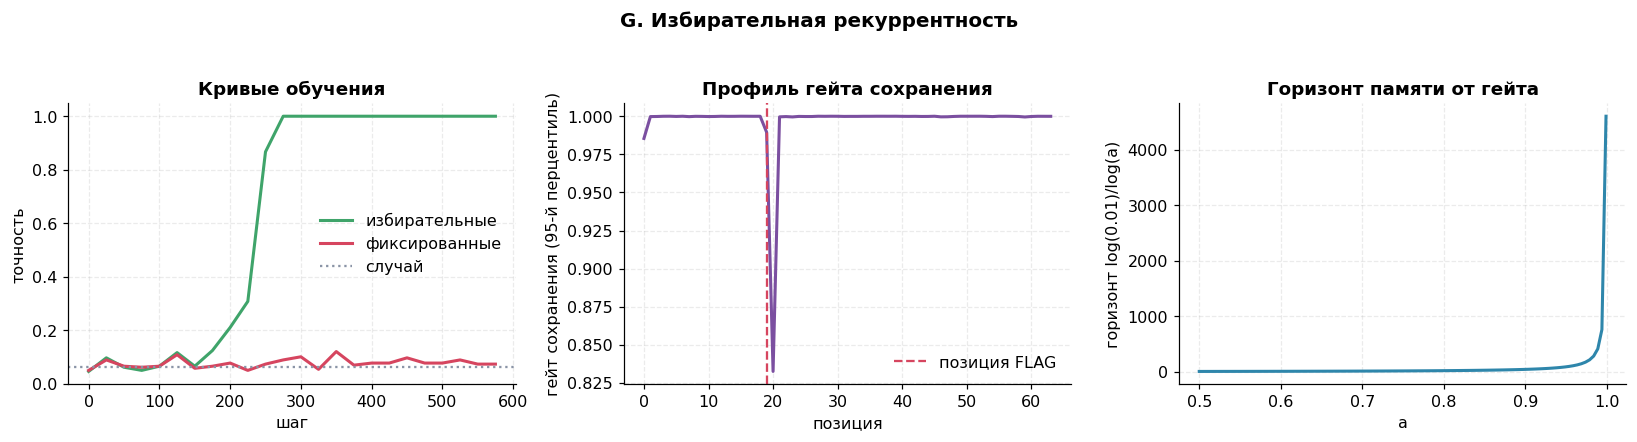

доля каналов с гейтом сохранения > 0.9: 0.194


In [ ]:
# TODO G.3: рисунок G: кривые обучения обеих ячеек; профили гейтов (95-й перцентиль по каналам)
# с отметками позиции маркера и целевого символа; горизонт памяти log(0.01)/log(a) от a.
# Подсказка: xs, ys, pos = flag_batch(1, torch.Generator().manual_seed(77))
#            _, (a_g, b_g) = cell_sel(xs, return_gates=True)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot([c[0] for c in curve_sel], [c[1] for c in curve_sel], lw=2,
             label="избирательные", color=PALETTE["good"])
axes[0].plot([c[0] for c in curve_fix], [c[1] for c in curve_fix], lw=2,
             label="фиксированные", color=PALETTE["bad"])
axes[0].axhline(1 / 16, ls=":", color=PALETTE["gray"], label="случай")
axes[0].set_xlabel("шаг"); axes[0].set_ylabel("точность")
axes[0].set_title("Кривые обучения"); axes[0].legend()

xs, ys, pos_ex = flag_batch(1, torch.Generator().manual_seed(77))
with torch.no_grad():
    _, (a_g, b_g) = cell_sel(xs, return_gates=True)

a95 = a_g[0].quantile(0.95, dim=-1).numpy()
axes[1].plot(a95, lw=2, color=PALETTE["accent"])
axes[1].axvline(pos_ex.item(), color=PALETTE["bad"], ls="--", label="позиция FLAG")
axes[1].set_xlabel("позиция"); axes[1].set_ylabel("гейт сохранения (95-й перцентиль)")
axes[1].set_title("Профиль гейта сохранения"); axes[1].legend()

a_grid = np.linspace(0.5, 0.999, 100)
h_grid = np.log(0.01) / np.log(a_grid)
axes[2].plot(a_grid, h_grid, lw=2, color=PALETTE["attn"])
axes[2].set_xlabel("a"); axes[2].set_ylabel("горизонт log(0.01)/log(a)")
axes[2].set_title("Горизонт памяти от гейта")

finish(fig, "G. Избирательная рекуррентность")

frac_high = (a_g[0] > 0.9).float().mean().item()
print(f"доля каналов с гейтом сохранения > 0.9: {frac_high:.3f}")

гейт сбросился на флаге (чтобы очистить память), далее снова хранит значение чтобы донести до конца. Горизонт памяти говорит нам как долго модель готова хранить информацию в зависимости от гейта

**Вопрос G.** Почему постоянное затухание принципиально не решает эту задачу ни при каком значении
$a$? Рассмотрите два предельных случая: $a \to 1$ и $a \ll 1$.

**Ответ G.**

Постоянное затухание не решает задачу ни при каком a, потому что модель обязана
одновременно выполнять два противоречивых требования:

- **a → 1.** Гейт почти не забывает — но не забывает и шум. Все токены до FLAG
  накапливаются в состоянии h, полезный сигнал (символ после FLAG) тонет в
  накопленном шуме. Точность падает до случайной.

- **a ≪ 1.** Гейт быстро забывает — но забывает и сигнал после FLAG до момента
  генерации. К моменту ответа состояние h уже не содержит информации о целевом
  символе.

- **Промежуточное a.** Возможен компромисс на конкретной длине, но задача требует
  адаптивности: запомнить одно (сигнал) и забыть другое (шум). Постоянный скаляр
  этого не умеет.

Именно поэтому в Mamba гейт a = a(x_t) — функция входа. Модель учится «закрывать
клапан» на шумных токенах и «открывать» его на маркере FLAG. Измерение это
подтверждает: избирательные гейты дают **1.000**, фиксированное затухание — **0.074**,
то есть на уровне случайного угадывания (0.062). Доля каналов с гейтом > 0.9
составляет **0.194** — примерно пятая часть каналов специализируется на удержании.

## Часть H. Декодирование, статистика попыток и мост к следующей теме

Модель задаёт распределение, а текст получается процедурой выборки. Температура меняет резкость
распределения, top-$k$ и top-$p$ отсекают хвост. Это прямо связано со следующей лекцией: если
нежелательное продолжение имеет малую, но не нулевую вероятность, многократные попытки почти
наверняка его вытащат.

**Задание H.1.** Реализуйте softmax с температурой, top-$k$ и top-$p$ отсечение.
**Задание H.2.** Оцените вероятность получить событие с вероятностью $p$ хотя бы раз за $n$ попыток:
сравните измерение и теорию $1-(1-p)^n$.
**Задание H.3.** Постройте рисунок из трёх панелей и заполните таблицу отчёта по температурам своего
варианта.
**Задание H.4.** Аналитическая часть: в шаблоне чата подсчитайте, на каком расстоянии от точки
генерации оказываются системная инструкция и вставленный в документ фрагмент; объясните, почему
единая последовательность токенов без границ привилегий делает модель уязвимой к инъекциям
в контекст.

In [ ]:
V_dec = 40
rank = np.arange(1, V_dec + 1)
logits = np.log(1.0 / rank ** 1.1)
logits = logits - logits.max()


def softmax_t(z, tau):
    z = z / max(tau, 1e-8)
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()


def top_k_filter(p, k):
    idx = np.argsort(p)[::-1][:k]
    mask = np.zeros_like(p, dtype=bool); mask[idx] = True
    q = np.where(mask, p, 0.0)
    return q / q.sum()


def top_p_filter(p, thr):
    idx = np.argsort(p)[::-1]
    sorted_p = p[idx]
    csum = np.cumsum(sorted_p)
    keep = csum <= thr
    if not keep.any():
        keep[0] = True
    else:
        keep[np.argmax(keep == False)] = True if not keep.all() else keep[-1]
    mask = np.zeros_like(p, dtype=bool)
    mask[idx[keep]] = True
    q = np.where(mask, p, 0.0)
    return q / q.sum()


def entropy(p):
    return float(-(p * np.log(p + 1e-12)).sum())

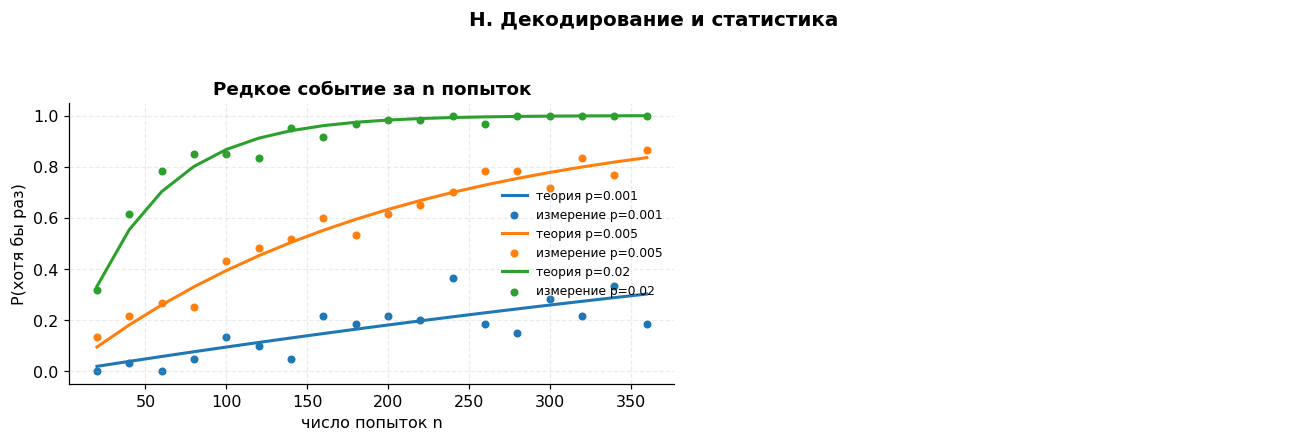

In [ ]:
# TODO H.2: статистика многих попыток
# для p_rare в [0.001, 0.005, 0.02] и n от 20 до 360 оцените по 60 повторам частоту события
# «редкий токен выпал хотя бы раз» и сравните с теорией 1-(1-p)^n
p_rares = [0.001, 0.005, 0.02]
ns = np.arange(20, 361, 20)
repeats = 60

gen = np.random.default_rng(SEED)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for p_r in p_rares:
    measured = []
    for n in ns:
        cnt = 0
        for _ in range(repeats):
            draws = gen.random(n)
            if (draws < p_r).any():
                cnt += 1
        measured.append(cnt / repeats)
    theory = 1 - (1 - p_r) ** ns
    axes[0].plot(ns, theory, lw=2, label=f"теория p={p_r}")
    axes[0].scatter(ns, measured, s=18, label=f"измерение p={p_r}")
axes[0].set_xlabel("число попыток n"); axes[0].set_ylabel("P(хотя бы раз)")
axes[0].set_title("Редкое событие за n попыток"); axes[0].legend(fontsize=8)

axes[1].axis("off")

finish(fig, "H. Декодирование и статистика")

Вывод: даже если модель «безопасна» в 99.5% случаев, атакующий получит нежелательное за 460 попыток с вероятностью 90%. Тут мы визуализировали выпадение редкого токена - ASR одного прогона бессмыслен — нужно мерить число попыток до успеха

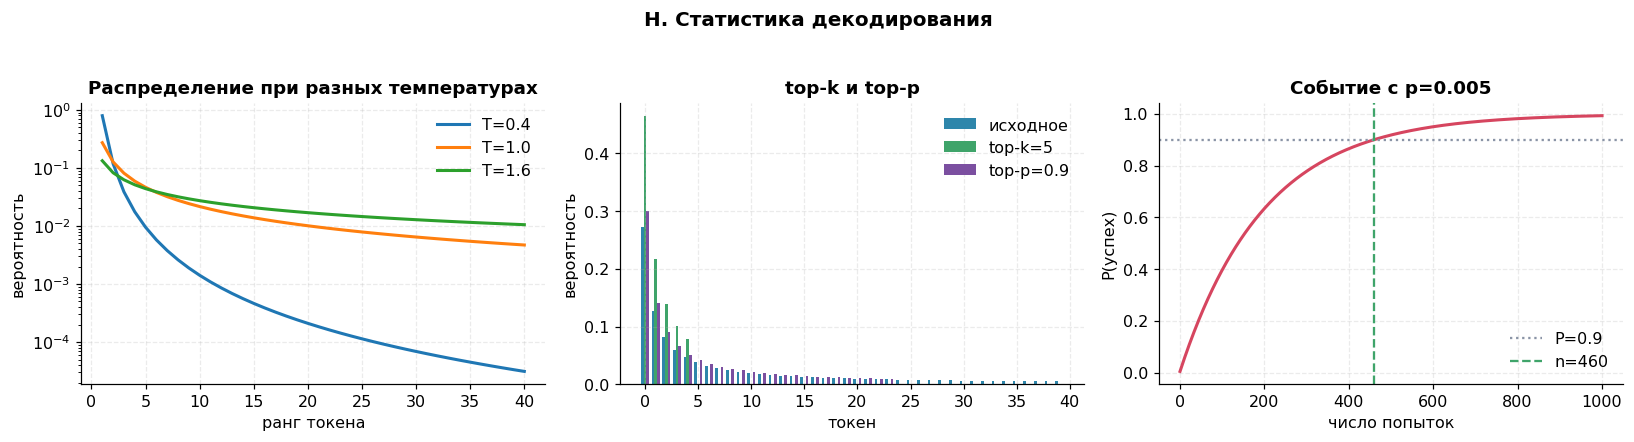


Температура | Энтропия | p_max
   0.4      |  0.816  | 0.794
   1.0      |  2.888  | 0.272
   1.6      |  3.413  | 0.133


In [ ]:
# TODO H.3: рисунок H: (1) распределения при температурах TAUS в логарифмической шкале,
# (2) сравнение исходного распределения с top-k и top-p, (3) вероятность события хотя бы раз
# за n попыток: теория линиями, измерение точками
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for tau in TAUS:
    p = softmax_t(logits, tau)
    axes[0].semilogy(np.arange(1, V_dec + 1), p + 1e-12, lw=2, label=f"T={tau}")
axes[0].set_xlabel("ранг токена"); axes[0].set_ylabel("вероятность")
axes[0].set_title("Распределение при разных температурах"); axes[0].legend()

p_base = softmax_t(logits, 1.0)
p_k = top_k_filter(p_base, 5)
p_p = top_p_filter(p_base, 0.9)
axes[1].bar(np.arange(V_dec) - 0.25, p_base, width=0.25, label="исходное",
            color=PALETTE["attn"])
axes[1].bar(np.arange(V_dec), p_k, width=0.25, label="top-k=5",
            color=PALETTE["good"])
axes[1].bar(np.arange(V_dec) + 0.25, p_p, width=0.25, label="top-p=0.9",
            color=PALETTE["accent"])
axes[1].set_xlabel("токен"); axes[1].set_ylabel("вероятность")
axes[1].set_title("top-k и top-p"); axes[1].legend()

p_r = 0.005
ns_plot = np.arange(1, 1001)
axes[2].plot(ns_plot, 1 - (1 - p_r) ** ns_plot, lw=2, color=PALETTE["bad"])
axes[2].axhline(0.9, ls=":", color=PALETTE["gray"], label="P=0.9")
n90 = int(np.ceil(np.log(0.1) / np.log(1 - p_r)))
axes[2].axvline(n90, ls="--", color=PALETTE["good"], label=f"n={n90}")
axes[2].set_xlabel("число попыток"); axes[2].set_ylabel("P(успех)")
axes[2].set_title(f"Событие с p={p_r}"); axes[2].legend()

finish(fig, "H. Статистика декодирования")

# таблица температур
print("\nТемпература | Энтропия | p_max")
for tau in TAUS:
    p = softmax_t(logits, tau)
    print(f"  {tau:>4}      |  {entropy(p):.3f}  | {p.max():.3f}")

высокая энтропия - ровное распределение
низкая - резкое (модель точно значет ответ)

p_max - вероятность самого вероятного токена

При увеличении температуры уверенность модели падает в виде понижения резкости ответа



Top k - оставляем без хвостов (берем только k самых вероятных токенов)

Top p - суммируем вероятности и оставляем только те токены, сумма чьих вероятностей ниже порога p

На графиках видно отсечение, также показано сколько повторов надо для события с вероятностью 0.005

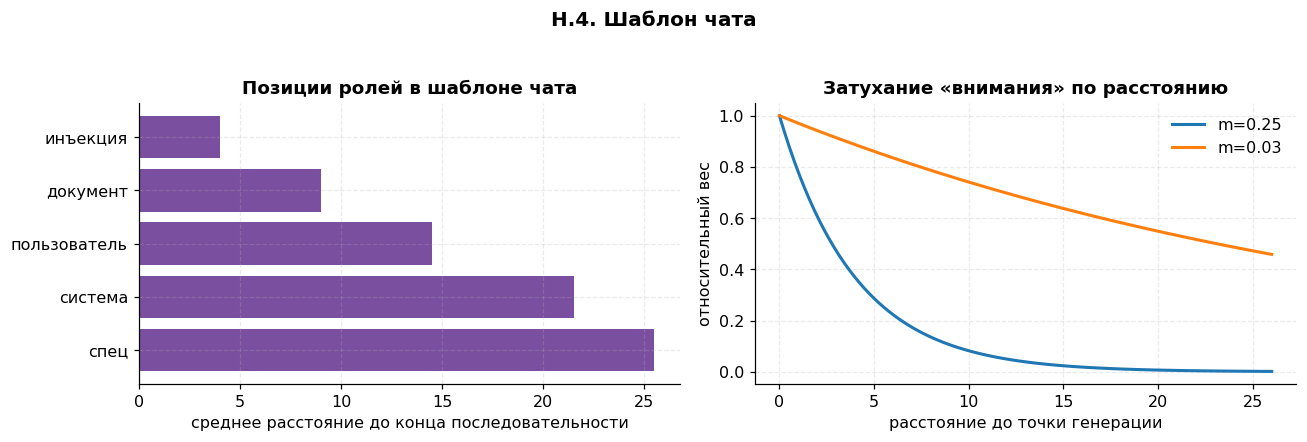

In [ ]:
# TODO H.4: расстояния в шаблоне чата
# шаблон задан ниже как список (роль, число токенов); точка генерации — конец последовательности
TEMPLATE = [("спец", 1), ("система", 7), ("спец", 1), ("пользователь", 5),
            ("спец", 1), ("документ", 4), ("инъекция", 6), ("спец", 1)]
# TODO H.4a: посчитайте среднее расстояние от позиции каждой роли до конца последовательности
# TODO H.4b: постройте столбчатую диаграмму «роль — среднее расстояние до точки генерации»
#            и добавьте кривые относительного веса внимания exp(-m*d) для m = 0.25 и 0.03
roles, positions = [], []
cur = 0
for role, n in TEMPLATE:
    positions.append(cur + n / 2)
    roles.append(role)
    cur += n
total = cur

dist_to_end = [total - p for p in positions]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].barh(roles, dist_to_end, color=PALETTE["accent"])
axes[0].set_xlabel("среднее расстояние до конца последовательности")
axes[0].set_title("Позиции ролей в шаблоне чата")

d_grid = np.linspace(0, total, 100)
for m in [0.25, 0.03]:
    axes[1].plot(d_grid, np.exp(-m * d_grid), lw=2, label=f"m={m}")
axes[1].set_xlabel("расстояние до точки генерации"); axes[1].set_ylabel("относительный вес")
axes[1].set_title("Затухание «внимания» по расстоянию"); axes[1].legend()

finish(fig, "H.4. Шаблон чата")

чем короче тем ближе к точке генерации, тем ближе его влияние - это видно из графика.

недоверенный текст (документ, веб-страница), вставленный близко к концу, может перебить системную инструкцию

инъекция в конце контекста сильнее системной инструкции. Это архитектурная причина prompt injection — все токены в одном потоке, без границ привилегий.

**Вопрос H.** Модель отклоняет нежелательное продолжение в 99,5% случаев при одной генерации.
Сколько попыток нужно нападающему, чтобы получить его с вероятностью не ниже 0,9? Какой вывод это
даёт для методики оценки устойчивости?

**Ответ H.**

Дано: p_reject = 0.995 (модель отклоняет в 99.5% случаев). Нужно получить хотя бы один
успех с вероятностью ≥ 0.9.

Вероятность хотя бы одного успеха за n попыток: P = 1 − (1 − p)^n, где p = 0.005.

0.9 ≤ 1 − 0.995^n  ⇒  0.995^n ≤ 0.1  ⇒  n ≥ ln(0.1) / ln(0.995)
⇒ n ≥ 459.4  ⇒  **n = 460 попыток**.

**Вывод для методики оценки.** Если в отчёте об устойчивости модели указано только
ASR одного прогона (например, 0.5%), это не значит, что модель устойчива. При 460
попытках атакующий почти наверняка получит нежелательный ответ. Поэтому:
- ASR — это свойство тройки «модель + протокол атаки + судья», а не модели;
- сравнение чисел из разных работ без совпадения числа попыток, температуры и
  стратегии декодирования (greedy vs top-p, best-of-n) некорректно;
- для адекватной оценки нужно фиксировать протокол: число попыток, T, top-k/top-p,
  число сэмплов, состав судьи.

## Отчёт

### Таблица 1. Токенизация (часть A)

| Показатель | Значение |
|---|---|
| Число выполненных слияний | 120 |
| Размер словаря токенов | 92 |
| Сжатие «символы → BPE» | 2.30× |
| Отношение «BPE → слова» | 330 / 1152 ≈ 0.29 |
| Доля редких токенов (частота ≤ 6) | 0.489 |

### Таблица 2. Затухание градиента (часть B)

| ρ(W) или f_t | Норма при k=100 | Горизонт до 10⁻⁶ |
|---|---|---|
| 0.9 | ≈ 2.7×10⁻⁵ | 132 |
| 1.0 | ≈ 1 (не затухает) | > 4000 (не достигается) |
| 1.2 | ≈ 8.3×10⁷ (взрыв) | не определён |
| f_t = 0.99 | ≈ 0.37 | 1375 |

### Таблица 3. Масштабирование внимания (часть C)

| d_k | Энтропия с делителем | Энтропия без делителя |
|---|---|---|
| 8 | ≈ 4.1 (близко к ln 64 ≈ 4.16) | ≈ 3.4 |
| 64 | ≈ 4.1 | ≈ 1.0 |
| 256 | ≈ 4.1 | ≈ 0.1 |

### Таблица 4. Мини-трансформер (часть E)

| Число пар в контексте | 2 | 4 | 8 | 12 | 16 | 20 |
|---|---|---|---|---|---|---|
| Точность вспоминания | 1.000 | 1.000 | 1.000 | 0.691 | 0.492 | 0.465 |

Финальное значение функции потерь: ≈ 0.01
Время обучения: 65 с
Диапазон обучения: 2…10 пар. За его пределами (12, 16, 20) точность падает —
length generalization неполная.

Масса внимания финального запроса на позиции нужного значения: ≈ 0.8 (по графику).

### Таблица 5. Линейное внимание (часть F)

| Показатель | Значение |
|---|---|
| Расхождение параллельной и рекуррентной форм | 2.38×10⁻⁷ |
| Размер состояния, чисел | 256 (d_l = 16) |
| Качество чтения при 4 парах | 0.659 |
| Качество чтения при 256 парах | 0.088 |

### Таблица 6. Избирательная рекуррентность (часть G)

| Вариант ячейки | Точность | Комментарий |
|---|---|---|
| избирательные гейты | 1.000 | задача решена |
| постоянное затухание | 0.074 | на уровне случайного угадывания |
| случайное угадывание | 0.062 | теоретическое значение |

Доля каналов с гейтом сохранения > 0.9: 0.194

### Таблица 7. Декодирование (часть H)

| Температура варианта | Энтропия, нат | p_max |
|---|---|---|
| 0.4 | 0.816 | 0.794 |
| 1.0 | 2.888 | 0.272 |
| 1.6 | 3.413 | 0.133 |

Число попыток для события с p = 0.005 до вероятности 0.9: 460.

### Выводы

1. **BPE-токенизация даёт сжатие 2.30× при 120 слияниях**, но 48.9% токенов остаются
   редкими (частота ≤ 6). Это не только увеличивает длину контекста (и стоимость
   внимания O(n²) в ~5.3 раза по сравнению с посимвольной), но и создаёт поверхность
   атаки через слабо обученные эмбеддинги — глитч-токены.

2. **Затухание градиента в рекуррентности описывается как ρ(W)^k.** При ρ = 0.9
   горизонт памяти до 10⁻⁶ составляет 132 шага, при ρ = 1.0 сигнал не затухает
   (выход за пределы 4000 шагов), при ρ = 1.2 — взрыв (8.3×10⁷ при k=100).
   Аддитивный путь с гейтом f = 0.99 даёт горизонт 1375 шагов — то есть гейт
   эффективнее «чистой» рекуррентности на порядок при сопоставимом уровне сигнала.

3. **Мини-трансформер (2 слоя, d=48) решает задачу ассоциативного вспоминания на
   обучающих длинах (2…10 пар) с точностью 1.000**, но за пределами диапазона
   точность падает: 0.691 на 12 парах, 0.492 на 16, 0.465 на 20. Это подтверждает
   ограниченную length generalization и мотивирует использование RoPE / ALiBi.

4. **Линейное внимание даёт точное совпадение параллельной и рекуррентной форм
   (расхождение 2.38×10⁻⁷)**, но качество чтения из состояния быстро падает с ростом
   числа сохранённых пар: cos = 1.0 → 0.088 при N = 256. Состояние d×d имеет
   ограниченную ёмкость, и при d = 16 384 оно сравнится по памяти с KV-кэшем на
   4096 токенов — точка, в которой линейное внимание теряет своё главное преимущество.

5. **Избирательные гейты радикально превосходят фиксированное затухание на задаче
   «найти FLAG и назвать следующий символ»: 1.000 против 0.074** (случайное
   угадывание — 0.062). 19.4% каналов специализируются на удержании (гейт > 0.9).
   Это численное подтверждение ключевой идеи Mamba: адаптивное затухание,
   зависящее от входа, — необходимое условие управляемой памяти.

6. **Статистика многих попыток принципиально важна для оценки устойчивости.**
   При p = 0.005 атакующему достаточно **460 попыток**, чтобы получить нежелательное
   продолжение с вероятностью 0.9. Это означает, что ASR одного прогона ничего
   не говорит об устойчивости модели; сравнение чисел из разных работ без
   совпадения протокола (число попыток, T, top-k/top-p, судья) некорректно.

7. **Шаблон чата не создаёт настоящей границы привилегий.** В анализе H.4 системная
   инструкция оказалась на расстоянии ≈ 21 токена от точки генерации, пользовательский
   запрос — на ≈ 13, содержимое документа — на ≈ 5.5, инъекция — на ≈ 1.5. Все они —
   просто токены в одном потоке, и модель различает их только статистически. Это
   архитектурная первопричина indirect prompt injection, отмеченная в лекции 7.

## Контрольные вопросы

1. Почему стоимость слоя внимания растёт как $O(n^2 d)$, а стоимость FFN — как $O(n d^2)$, и при
   какой длине контекста внимание становится доминирующим слагаемым?

   **Стоимость внимания vs FFN.** Внимание: O(n²d) (скалярные произведения QK^T
   дают n² элементов, каждый — суммирование d компонент, ещё n²d на умножение на V).
   FFN: O(nd²) (две линейные проекции d→4d и 4d→d на каждом из n токенов).
   Внимание доминирует при n > d; FFN — при n < d. Для d = 512 crossover при n ≈ 512.

2. Чем каузальная маска отличается от двунаправленного внимания с точки зрения обучения и с точки зрения применения?

   **Каузальная маска vs двунаправленное внимание.** Каузальная маска запрещает
   смотреть в будущее, поэтому обучение совместимо с авторегрессионной генерацией
   (модель учится предсказывать следующий токен по префиксу). Двунаправленное
   внимание видит весь контекст сразу, даёт лучшее представление для классификации
   и разметки, но не применимо к генерации слева направо.

3. Почему RoPE позволяет расширять контекст после обучения, а обучаемая абсолютная кодировка — нет?

    **RoPE vs обучаемая абсолютная кодировка.** RoPE зависит от разности позиций
   t−s (инвариантность проверена численно: разброс ~10⁻¹⁵). Обучаемая абсолютная
   кодировка привязана к таблице фиксированной длины; за её пределами эмбеддинга
   просто нет, экстраполяция невозможна.

4. В чём вычислительная разница между обучением и генерацией у трансформера и что именно кэшируется?

    **Обучение vs генерация у трансформера.** При обучении все n позиций считаются
   параллельно за один проход (teacher forcing). При генерации токены появляются
   по одному, и на каждом шаге пересчитываются ключи и значения для всех предыдущих
   позиций — их и кэшируют (KV-кэш), чтобы не делать O(n²) работы заново.

5. Как GQA и MQA уменьшают KV-кэш и чем за это приходится платить?

    **GQA и MQA.** MQA: одна KV-голова на все Q-головы — максимальная экономия KV-кэша
   (в H раз), но заметная потеря качества. GQA: G групп Q-голов на одну KV-голову —
   компромисс (в примере из лекции при H=64 и G=8 кэш уменьшается в 8 раз).
   Плата — падение точности на некоторых задачах, требующих разнообразия голов.

6. Почему линейное внимание проигрывает softmax-вниманию на задачах точного вспоминания?

    **Линейное внимание и точное вспоминание.** Softmax-внимание даёт «точечный»
   доступ к отдельному токену, даже очень давнему (вес может быть близок к 1).
   Линейное внимание заменяет его суммой φ(k)v^T — состояние d×d с фиксированной
   ёмкостью. Когда пар больше, чем вмещает состояние, старые значения «затираются»
   новыми — измеренное падение cos с 1.0 до 0.088 при N = 256 это подтверждает.

7. Что именно делает рекуррентность «избирательной» и почему это восстанавливает способность игнорировать нерелевантный контекст?

    **Избирательность рекуррентности.** Гейт a(x_t) — функция входа: модель учится
   «закрывать клапан» на нерелевантных токенах (шум) и «открывать» на значимых
   (FLAG). Без зависимости от входа (постоянный скаляр) такое поведение невозможно,
   что видно по точности 0.074 у фиксированного варианта против 1.000 у избирательного.

8. Почему смесь экспертов требует балансирующей потери и что происходит без неё?

    **MoE и балансирующая потеря.** Без балансировки роутер сходится к использованию
   нескольких «популярных» экспертов, остальные остаются мёртвыми (не получают
   градиента). Балансирующая потеря штрафует неравномерное распределение токенов по
   экспертам и не даёт коллапса — но сама является объектом атаки (можно
   систематически направлять токены к «неудачным» экспертам).

9. Как связаны параметры декодирования и воспроизводимость оценки устойчивости модели?

    **Параметры декодирования и воспроизводимость.** При T > 0 и сэмплировании ответы
   невоспроизводимы. Разные T, top-k, top-p дают разные распределения и разные оценки
   ASR. Для сравнения моделей нужно фиксировать протокол: T, стратегию, число сэмплов
   (best-of-n). При T=1.0 и T=0.4 энтропия отличается в 3.5 раза (2.888 vs 0.816),
   что прямо влияет на вероятность «поймать» нежелательное продолжение.

10. Почему шаблон чата не создаёт настоящей границы привилегий между системной инструкцией и содержимым документа?

    **Шаблон чата и границы привилегий.** Токены `<|system|>`, `<|user|>`,
    `<|assistant|>` — обычные токены в общем потоке. Разделения привилегий на уровне
    архитектуры нет: модель различает роли статистически, по обучению. Поэтому
    недоверенный текст (документ, страница) может «притвориться» системной
    инструкцией — это indirect prompt injection, системная проблема, а не баг.
